In [1]:
# 安装并导入 DuckDB
!pip install duckdb -q
import duckdb
print(f"DuckDB 版本: {duckdb.__version__}")

DuckDB 版本: 1.4.5


In [2]:
import pandas as pd

# 读取我们在 Day 3 构建好的宽表
df = pd.read_csv('../data/processed/orders_master.csv')
print(f"宽表形状: {df.shape}")

# 创建 DuckDB 连接，并将 df 注册为一个名为 'orders' 的虚拟表
con = duckdb.connect()
con.register('orders', df)

# 简单验证一下 SQL 能不能用
con.execute("SELECT COUNT(*) AS total_orders FROM orders").fetchdf()

宽表形状: (96478, 21)


,total_orders
0,96478


In [6]:
# 确保时间列是 datetime 类型后再注册
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# 重新注册表（覆盖之前的视图）
con.register('orders', df)

# 此时原来的 SQL 就能直接跑了
sql_1 = """
SELECT 
    date_trunc('month', order_purchase_timestamp) AS order_month,
    COUNT(order_id) AS order_count,
    SUM(total_amount) AS gmv,
    AVG(total_amount) AS avg_order_value
FROM orders
WHERE order_purchase_timestamp >= '2017-01-01' 
  AND order_purchase_timestamp < '2018-09-01'
GROUP BY order_month
ORDER BY order_month
"""

monthly_trend = con.execute(sql_1).fetchdf()
print(monthly_trend.head(10))

  order_month  order_count        gmv  avg_order_value
0  2017-01-01          750  127482.37       169.976493
1  2017-02-01         1653  271239.32       164.089123
2  2017-03-01         2546  414330.95       162.738001
3  2017-04-01         2303  390812.40       169.697091
4  2017-05-01         3546  566851.40       159.856571
5  2017-06-01         3135  490050.37       156.315907
6  2017-07-01         3872  566299.08       146.254928
7  2017-08-01         4193  645832.36       154.026320
8  2017-09-01         4150  701077.49       168.934335
9  2017-10-01         4478  751117.01       167.734929


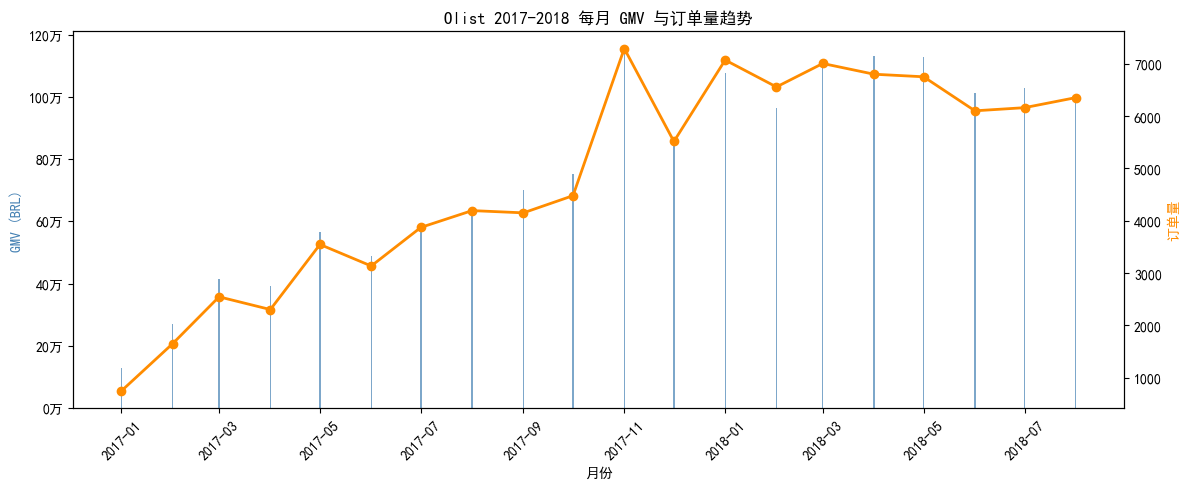

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 解决 Windows 下的中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

fig, ax1 = plt.subplots(figsize=(12, 5))

# 画 GMV（柱状图，左轴）
ax1.bar(monthly_trend['order_month'], monthly_trend['gmv'], color='steelblue', alpha=0.7, label='GMV')
ax1.set_xlabel('月份')
ax1.set_ylabel('GMV (BRL)', color='steelblue')
ax1.tick_params(axis='x', rotation=45)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x/10000:.0f}万'))

# 画订单量（折线图，右轴）
ax2 = ax1.twinx()
ax2.plot(monthly_trend['order_month'], monthly_trend['order_count'], color='darkorange', marker='o', linewidth=2, label='订单量')
ax2.set_ylabel('订单量', color='darkorange')

plt.title('Olist 2017-2018 每月 GMV 与订单量趋势')
fig.tight_layout()
plt.show()

In [8]:
# 把需要的原始表加载进 DuckDB
items = pd.read_csv('../data/raw/olist_order_items_dataset.csv')
products = pd.read_csv('../data/raw/olist_products_dataset.csv')
translation = pd.read_csv('../data/raw/product_category_name_translation.csv')

con.register('items', items)
con.register('products', products)
con.register('translation', translation)
con.register('orders_clean', df) # 刚才的宽表

sql_2 = """
SELECT 
    t.product_category_name_english AS category,
    COUNT(DISTINCT i.order_id) AS order_count,
    SUM(i.price) AS total_sales,
    ROUND(SUM(i.price) / (SELECT SUM(price) FROM items) * 100, 2) AS sales_pct
FROM items i
JOIN products p ON i.product_id = p.product_id
JOIN translation t ON p.product_category_name = t.product_category_name
GROUP BY category
ORDER BY total_sales DESC
LIMIT 10
"""

top_categories = con.execute(sql_2).fetchdf()
top_categories

,category,order_count,total_sales,sales_pct
0,health_beauty,8836,1258681.34,9.26
1,watches_gifts,5624,1205005.68,8.87
2,bed_bath_table,9417,1036988.68,7.63
3,sports_leisure,7720,988048.97,7.27
4,computers_accessories,6689,911954.32,6.71
5,furniture_decor,6449,729762.49,5.37
6,cool_stuff,3632,635290.85,4.67
7,housewares,5884,632248.66,4.65
8,auto,3897,592720.11,4.36
9,garden_tools,3518,485256.46,3.57


In [10]:
# 1. 重新读取评论表并聚合
reviews = pd.read_csv('../data/raw/olist_order_reviews_dataset.csv')
reviews_agg = reviews.groupby('order_id').agg(
    review_count=('review_id', 'count'),
    review_score_mean=('review_score', 'mean'),
    review_score_min=('review_score', 'min')
).reset_index()

# 2. 把评分数据合并进当前的 df 宽表
df = df.merge(reviews_agg, on='order_id', how='left')

# 3. 重新注册到 DuckDB（覆盖之前的表）
con.register('orders', df)

# 4. 验证字段是否成功加入
print("评分字段是否加入成功:", 'review_score_mean' in df.columns)

# 5. （可选）顺便把补全后的宽表重新保存一次，覆盖旧的
df.to_csv('../data/processed/orders_master.csv', index=False)
print("宽表已更新并保存！")

评分字段是否加入成功: True
宽表已更新并保存！


In [11]:
sql_3 = """
SELECT 
    CASE 
        WHEN is_late = FALSE THEN '0. 未延迟'
        WHEN (delivery_days - estimated_days) BETWEEN 1 AND 3 THEN '1. 延迟 1-3 天'
        WHEN (delivery_days - estimated_days) BETWEEN 4 AND 7 THEN '2. 延迟 4-7 天'
        WHEN (delivery_days - estimated_days) BETWEEN 8 AND 15 THEN '3. 延迟 8-15 天'
        ELSE '4. 延迟 15 天以上'
    END AS delay_bucket,
    COUNT(order_id) AS order_count,
    ROUND(AVG(review_score_mean), 2) AS avg_review_score,
    ROUND(AVG(delivery_days), 1) AS avg_delivery_days
FROM orders
WHERE review_score_mean IS NOT NULL
GROUP BY delay_bucket
ORDER BY delay_bucket
"""

delay_impact = con.execute(sql_3).fetchdf()
print(delay_impact)

   delay_bucket  order_count  avg_review_score  avg_delivery_days
0        0. 未延迟        88685              4.29               10.5
1   1. 延迟 1-3 天         2330              3.61               21.5
2   2. 延迟 4-7 天         1747              2.23               26.8
3  3. 延迟 8-15 天         1809              1.71               34.0
4  4. 延迟 15 天以上         1261              1.72               54.9


C:\Users\admin\AppData\Local\Temp\ipykernel_36808\352623697.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='delay_bucket', y='avg_review_score', data=delay_impact, palette='Reds_r')


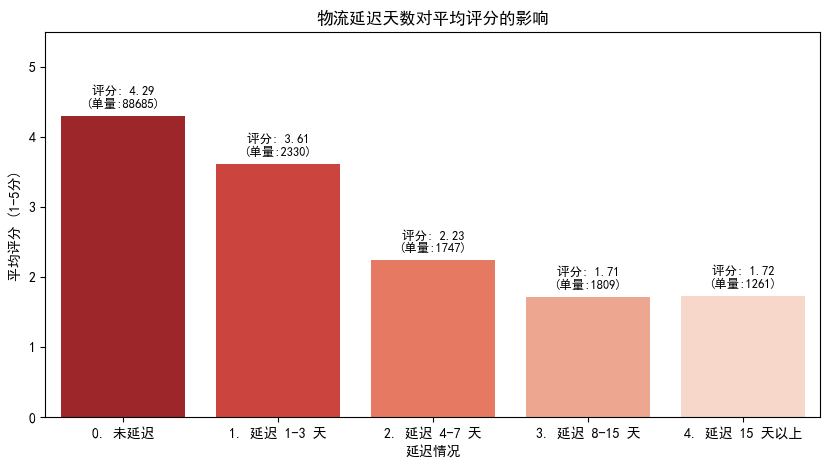

In [13]:
!pip install seaborn -q
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 5))
# 画出柱状图
ax = sns.barplot(x='delay_bucket', y='avg_review_score', data=delay_impact, palette='Reds_r')

# 在柱子上标出具体的评分和订单量
for i, p in enumerate(ax.patches):
    ax.annotate(f"评分: {delay_impact['avg_review_score'][i]}\n(单量:{delay_impact['order_count'][i]})", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=9, xytext=(0, 5), textcoords='offset points')

plt.title('物流延迟天数对平均评分的影响')
plt.xlabel('延迟情况')
plt.ylabel('平均评分 (1-5分)')
plt.ylim(0, 5.5)
plt.show()

In [14]:
# 我们先找出整个数据集中最后一天的购买时间，作为计算 R 的“快照日期”
# 因为数据是历史数据，不能用今天的真实时间
snapshot_date_sql = "SELECT MAX(order_purchase_timestamp::DATE) + INTERVAL 1 DAY AS snapshot_date FROM orders"
snapshot_date = con.execute(snapshot_date_sql).fetchdf()['snapshot_date'][0]
print(f"数据的快照日期是: {snapshot_date}")

sql_rfm_base = f"""
WITH user_orders AS (
    -- 这里注意：我们用的是 customer_unique_id（真实用户），而不是 customer_id（每次下单生成的ID）
    SELECT 
        customer_unique_id AS user_id,
        MAX(order_purchase_timestamp::DATE) AS last_purchase_date,
        COUNT(DISTINCT order_id) AS frequency,
        SUM(total_amount) AS monetary
    FROM orders
    WHERE order_status = 'delivered'
    GROUP BY customer_unique_id
)
SELECT 
    user_id,
    -- 1. R值 (Recency)：用快照日期减去最后购买日期，得到天数
    DATE_DIFF('day', last_purchase_date, DATE '{snapshot_date}') AS recency,
    -- 2. F值 (Frequency)：购买频次
    frequency,
    -- 3. M值 (Monetary)：消费总额
    monetary
FROM user_orders
"""

rfm_base = con.execute(sql_rfm_base).fetchdf()
print(rfm_base.head())

数据的快照日期是: 2018-08-30 00:00:00
                            user_id  recency  frequency  monetary
0  7973a6ba9c81ecaeb3d628c33c7c7c48      345          2    115.74
1  c89cf1a054b60f1d893617b0b1a140d7      273          1    286.54
2  344fecfc1b158f40bd95550e62547fda      208          1    165.40
3  fb20bf5c01fbc8bb8ab3ec1e4104c9d5      211          1    170.10
4  e20247a9f1cdb71d4415f2a0903212f9      174          1    363.96


In [15]:
sql_repurchase = """
SELECT 
    COUNT(user_id) AS total_users,
    SUM(CASE WHEN frequency > 1 THEN 1 ELSE 0 END) AS repeat_users,
    ROUND(SUM(CASE WHEN frequency > 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(user_id), 2) AS repurchase_rate
FROM (
    SELECT customer_unique_id AS user_id, COUNT(DISTINCT order_id) AS frequency
    FROM orders
    GROUP BY customer_unique_id
)
"""
repurchase_stats = con.execute(sql_repurchase).fetchdf()
print(repurchase_stats)

   total_users  repeat_users  repurchase_rate
0        93358        2801.0              3.0


In [16]:
import pandas as pd
import numpy as np

# 复制一份刚才查出来的基础数据
rfm = rfm_base.copy()

# ==========================================
# 1. 给 R、F、M 打分 (1-5分)
# 为什么用 rank(method='first')？
# 因为很多人 F 都是 1，直接切分位数会报错，rank 保证了每个值都有唯一的排名。
# ==========================================

# R 评分：越近越好（recency 越小，打分越高）。所以 labels 是倒序的 [5,4,3,2,1]
rfm['R_Score'] = pd.qcut(rfm['recency'].rank(method='first'), q=5, labels=[5, 4, 3, 2, 1])

# F 评分：买的次数越多越好（frequency 越大，打分越高）
rfm['F_Score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

# M 评分：花的钱越多越好（monetary 越大，打分越高）
rfm['M_Score'] = pd.qcut(rfm['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

# 将评分转为整数型（因为 qcut 出来的是 category 类型）
rfm['R_Score'] = rfm['R_Score'].astype(int)
rfm['F_Score'] = rfm['F_Score'].astype(int)
rfm['M_Score'] = rfm['M_Score'].astype(int)

# 将三个分数拼成一个字符串，比如 "555" 代表 R=5, F=5, M=5
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# 计算 RFM 总分
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

print(rfm[['user_id', 'recency', 'frequency', 'monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']].head())

                            user_id  recency  frequency  monetary  R_Score  \
0  7973a6ba9c81ecaeb3d628c33c7c7c48      345          2    115.74        2   
1  c89cf1a054b60f1d893617b0b1a140d7      273          1    286.54        2   
2  344fecfc1b158f40bd95550e62547fda      208          1    165.40        3   
3  fb20bf5c01fbc8bb8ab3ec1e4104c9d5      211          1    170.10        3   
4  e20247a9f1cdb71d4415f2a0903212f9      174          1    363.96        4   

   F_Score  M_Score  RFM_Score  
0        5        3         10  
1        1        5          8  
2        1        4          8  
3        1        4          8  
4        1        5         10  


In [17]:
# 定义一个分层函数（基于 R 和 F 的分数组合，这是业界常用的 8 大分层法）
def segment_user(row):
    r = row['R_Score']
    f = row['F_Score']
    
    # 简单规则示例：如果 R>=4 且 F>=4，说明最近买过且买得多 -> 重要价值客户
    if r >= 4 and f >= 4:
        return '重要价值客户'
    elif r < 4 and f >= 4:
        return '重要挽留客户'
    elif r >= 4 and f < 4:
        return '重要发展客户'
    elif r < 3 and f < 3:
        return '一般流失客户'
    else:
        return '一般客户'

# axis=1 表示一行一行地应用这个函数
rfm['Customer_Segment'] = rfm.apply(segment_user, axis=1)

# 统计每个层级的用户数和总消费额
segment_summary = rfm.groupby('Customer_Segment').agg(
    user_count=('user_id', 'count'),
    total_monetary=('monetary', 'sum')
).reset_index()

# 计算占比
segment_summary['user_pct'] = (segment_summary['user_count'] / segment_summary['user_count'].sum() * 100).round(2)
segment_summary['monetary_pct'] = (segment_summary['total_monetary'] / segment_summary['total_monetary'].sum() * 100).round(2)

# 按总消费金额降序排列
segment_summary = segment_summary.sort_values('total_monetary', ascending=False)
print(segment_summary)

  Customer_Segment  user_count  total_monetary  user_pct  monetary_pct
4           重要挽留客户       22225      3743715.76     23.81         24.28
3           重要发展客户       22225      3685010.78     23.81         23.90
0             一般客户       18852      2931354.90     20.19         19.01
2           重要价值客户       15118      2641719.45     16.19         17.13
1           一般流失客户       14938      2417972.86     16.00         15.68


In [18]:
# 筛选出“重要价值客户”
high_value_users = rfm[rfm['Customer_Segment'] == '重要价值客户']

# 计算他们的人数占比和消费金额占比
high_value_user_pct = len(high_value_users) / len(rfm) * 100
high_value_monetary_pct = high_value_users['monetary'].sum() / rfm['monetary'].sum() * 100

print(f"重要价值客户人数占比: {high_value_user_pct:.2f}%")
print(f"重要价值客户贡献销售额占比: {high_value_monetary_pct:.2f}%")

重要价值客户人数占比: 16.19%
重要价值客户贡献销售额占比: 17.13%


In [19]:
# 1. 重新定义打分逻辑
def calculate_rfm_scores(row):
    # R 打分 (1-5分)：根据天数分箱
    if row['recency'] <= 30: r = 5
    elif row['recency'] <= 90: r = 4
    elif row['recency'] <= 180: r = 3
    elif row['recency'] <= 365: r = 2
    else: r = 1

    # F 打分 (1-5分)：针对 Olist 极低复购率定制
    if row['frequency'] == 1: f = 1
    elif row['frequency'] == 2: f = 3
    elif row['frequency'] >= 3: f = 5

    # M 打分 (1-5分)：根据金额分箱（这里用 qcut 是可以的，因为金额分布相对连续）
    if row['monetary'] <= 50: m = 1
    elif row['monetary'] <= 100: m = 2
    elif row['monetary'] <= 200: m = 3
    elif row['monetary'] <= 500: m = 4
    else: m = 5
    
    return pd.Series([r, f, m])

# 应用新规则
rfm[['R_Score', 'F_Score', 'M_Score']] = rfm.apply(calculate_rfm_scores, axis=1)

# 2. 重新定义分层规则
def segment_user(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    
    # 如果是只买过一次的人，统统归为“一般/流失客户”
    if f == 1:
        if r >= 4: return '新晋客户'
        else: return '一般流失客户'
    
    # 买过多次的人，才配进入“重要”系列
    if r >= 4 and m >= 4: return '重要价值客户'
    elif r < 4 and m >= 4: return '重要挽留客户'
    elif r >= 4 and m < 4: return '重要发展客户'
    else: return '一般保持客户'

rfm['Customer_Segment'] = rfm.apply(segment_user, axis=1)

# 3. 重新统计
segment_summary = rfm.groupby('Customer_Segment').agg(
    user_count=('user_id', 'count'),
    total_monetary=('monetary', 'sum')
).reset_index()

segment_summary['user_pct'] = (segment_summary['user_count'] / segment_summary['user_count'].sum() * 100).round(2)
segment_summary['monetary_pct'] = (segment_summary['total_monetary'] / segment_summary['total_monetary'].sum() * 100).round(2)

# 按消费金额降序
segment_summary = segment_summary.sort_values('total_monetary', ascending=False)
print(segment_summary)

# 重新计算“重要价值客户”的贡献
high_value = rfm[rfm['Customer_Segment'] == '重要价值客户']
print(f"\n重要价值客户人数占比: {len(high_value) / len(rfm) * 100:.2f}%")
print(f"重要价值客户贡献销售额占比: {high_value['monetary'].sum() / rfm['monetary'].sum() * 100:.2f}%")

  Customer_Segment  user_count  total_monetary  user_pct  monetary_pct
1           一般流失客户       72778     11656405.41     77.96         75.59
2             新晋客户       17779      2899180.88     19.04         18.80
5           重要挽留客户        1233       538939.33      1.32          3.50
3           重要价值客户         372       164798.47      0.40          1.07
0           一般保持客户         957       128304.42      1.03          0.83
4           重要发展客户         239        32145.24      0.26          0.21

重要价值客户人数占比: 0.40%
重要价值客户贡献销售额占比: 1.07%
